In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob

In [2]:
graph_type = 'ER'
coup_type = 'gauss'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")

beta_uni = 0.334619


In [3]:
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/tmp/nb_star_DS_{graph_type}_{coup_type}_d{d}_N*.csv')]
df = pd.concat(dfs, ignore_index=True)
df

,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,time,mean_nb_star,std_nb_star,mean_nb_confs,std_nb_confs
0,0.30,F_beta_Glauber,False,100,25,100000000,10000,25,0,10000.00,0.000000,99.0,0.0
1,0.30,F_beta_Glauber,False,100,25,100000000,10000,25,100000,9999.56,0.496387,99.0,0.0
2,0.30,F_beta_Glauber,False,100,25,100000000,10000,25,200000,2416.48,91.397645,99.0,0.0
3,0.30,F_beta_Glauber,False,100,25,100000000,10000,25,300000,1252.72,115.139053,99.0,0.0
4,0.30,F_beta_Glauber,False,100,25,100000000,10000,25,400000,750.76,98.835734,99.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5000,0.34,F_beta_Glauber,False,100,25,100000000,10000,25,99600000,0.00,0.000000,1.0,0.0
5001,0.34,F_beta_Glauber,False,100,25,100000000,10000,25,99700000,0.00,0.000000,1.0,0.0
5002,0.34,F_beta_Glauber,False,100,25,100000000,10000,25,99800000,0.00,0.000000,1.0,0.0
5003,0.34,F_beta_Glauber,False,100,25,100000000,10000,25,99900000,0.00,0.000000,1.0,0.0


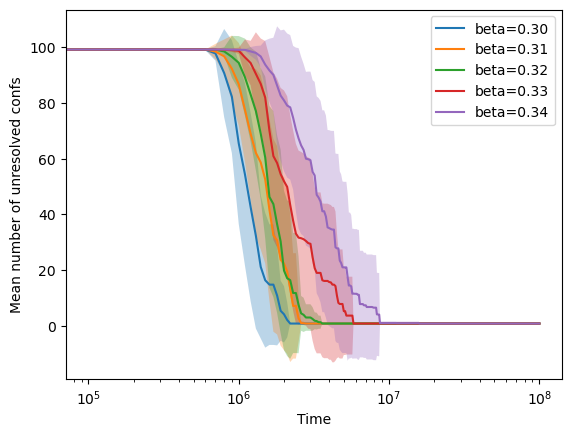

In [5]:
N_plotted = 10000
mask = (
    (df['N'] == N_plotted) 
)
df_filtered = df[mask]

for beta in df['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_confs'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_confs'] - sub_df['std_nb_confs'],
                     sub_df['mean_nb_confs'] + sub_df['std_nb_confs'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of unresolved confs')
plt.legend()
plt.show()

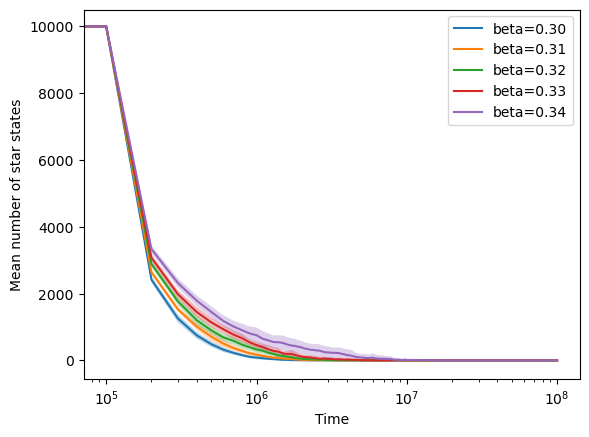

In [6]:
N_plotted = 10000
mask = (
    (df['N'] == N_plotted) 
)
df_filtered = df[mask]

for beta in df['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of star states')
plt.legend()
plt.show()

C = 0.013, R²=0.9538


/tmp/ipykernel_99001/490252473.py:6: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)


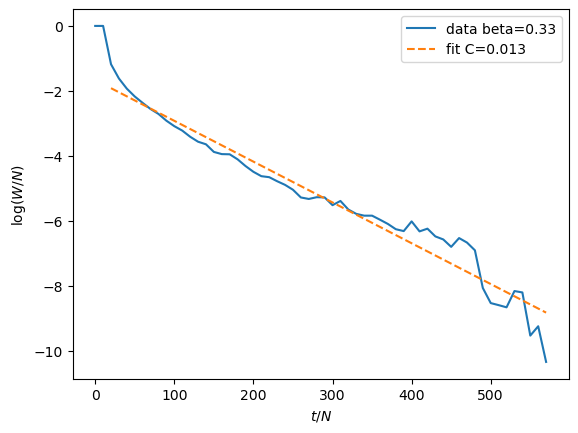

In [7]:
beta = 0.33
sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
N = sub_df['N'].values[0]

t_over_N = sub_df['time'].values / N
log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)

from scipy.stats import linregress

mask = (t_over_N > 10)  & (log_W_over_N > -np.inf) & np.isfinite(log_W_over_N)
slope, intercept, r, p, se = linregress(t_over_N[mask], log_W_over_N[mask])
C = -slope
print(f"C = {C:.3f}, R²={r**2:.4f}")

plt.plot(t_over_N, log_W_over_N, label=f'data beta={beta:.2f}')
plt.plot(t_over_N[mask], intercept + slope * t_over_N[mask], '--', label=f'fit C={C:.3f}')
plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend()
plt.show()

In [ ]:
for beta in sorted([0.31]):
    for N in [1000, 10000, 100000]:
        csv_path = f"../results/tmp/nb_star_ER_{coup_type}_d{d}_N{N}.csv"
        df = pd.read_csv(csv_path)
        sub_df = df[(df['beta'] == beta) & (df['N'] == N)].sort_values('time')
        t_over_N = sub_df['time'].values / N
        log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
        plt.plot(t_over_N, log_W_over_N, label=f'beta={beta:.2f}, N={N}')

plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend(fontsize=8)
plt.show()